In [2]:
import h5py 
import numpy as np
import matplotlib 

file = h5py.File(r'D:\MRI-Brain-Reconstruction\datasets\multicoil_train\file_brain_AXFLAIR_200_6002452.h5', 'r')
print(list(file.keys()))

print(file['kspace'])
print(file['reconstruction_rss'].shape)




['ismrmrd_header', 'kspace', 'reconstruction_rss']
<HDF5 dataset "kspace": shape (16, 20, 640, 320), type "<c8">
(16, 320, 320)


K-space shape: (16, 20, 640, 320)
Reference shape: (16, 320, 320)


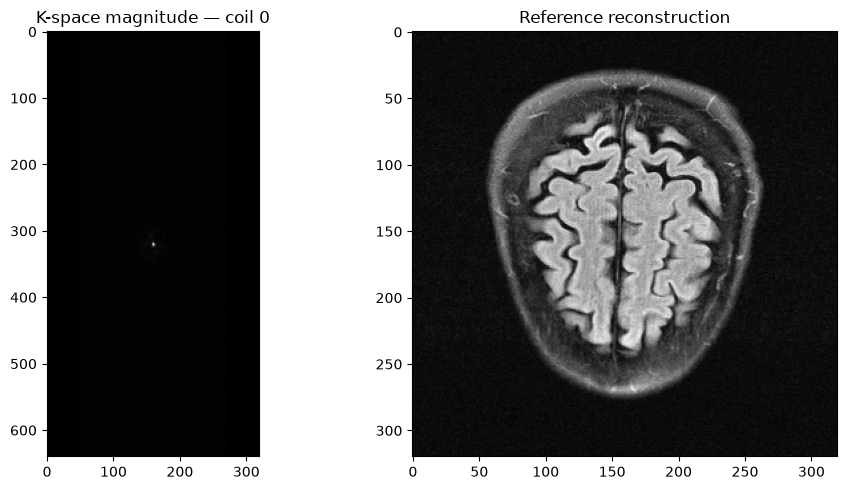

In [29]:
import h5py
import matplotlib.pyplot as plt
import numpy as np


file = h5py.File(r'D:\MRI-Brain-Reconstruction\datasets\multicoil_train\file_brain_AXFLAIR_200_6002452.h5', "r") 
kspace = file["kspace"][:]
reference = file["reconstruction_rss"][:]

print("K-space shape:", kspace.shape)
print("Reference shape:", reference.shape)

# Get slice in the middle 
slice_idx = reference.shape[0] // 2

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
#get kspace at index and coil 0 
plt.imshow(np.abs(kspace[slice_idx, 0]), cmap="gray")
plt.title("K-space magnitude — coil 0")

plt.subplot(1, 2, 2)
#get reference at index and ALL coils
plt.imshow(reference[slice_idx], cmap="gray")
plt.title("Reference reconstruction")


plt.tight_layout()
plt.show()

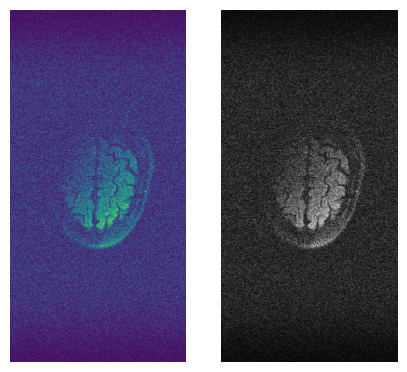

In [37]:
#Visualize a single coil 

#Get Coil Index 
coil = kspace[slice_idx, 0]

#fftshift magnitude back to center pos
coil_image = np.fft.fftshift(
    #Apply IFFT
    np.fft.ifft2(
        #ifftshift to shift center arrangment into IFFT shape
        np.fft.ifftshift(coil)
        )
    )
plt.figure(figsize=(5,10))
plt.subplot(1,2,1)
plt.imshow(np.abs(coil_image))
plt.axis('off')
plt.subplot(1,2,2)
plt.imshow(np.abs(coil_image), cmap = "grey")
plt.axis('off')
plt.show()

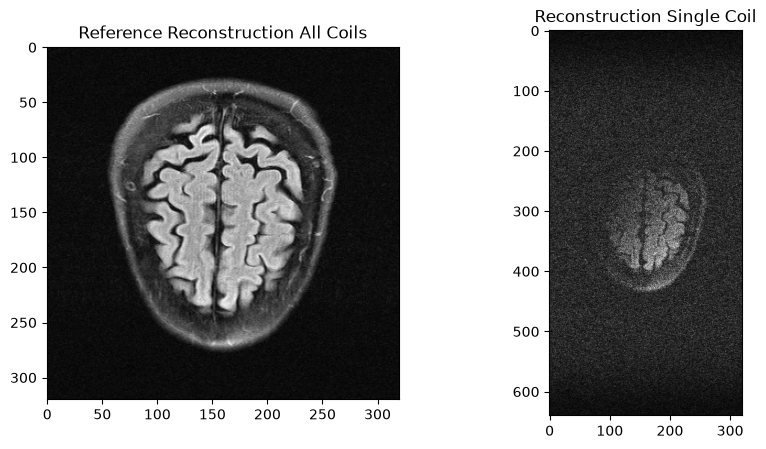

kspace shape: (16, 20, 640, 320)
coil_kspace shape: (640, 320)
coil_image shape: (640, 320)
reference shape: (16, 320, 320)
Coil magnitude range: 1.5857305e-11 5.242259e-08
Reference range: 9.724947e-06 0.0004375913


In [ ]:
#Compare 
plt.figure(figsize=(10, 5))

plt.subplot(1,2,1)
plt.imshow(reference[slice_idx], cmap="grey")
plt.title("Reference Reconstruction All Coils")

plt.subplot(1,2,2)
plt.imshow(np.abs(coil_image), cmap ="grey")
plt.title("Reconstruction Single Coil")
plt.show()

print("kspace shape:", kspace.shape)
print("coil_kspace shape:", coil.shape)
print("coil_image shape:", coil_image.shape)
print("reference shape:", reference.shape)

print("Coil magnitude range:",
      np.abs(coil_image).min(),
      np.abs(coil_image).max())

print("Reference range:",
      reference.min(),
      reference.max())